# 02 · Model selection with nested cross-validation

Four model families are compared for each of the five functional attributes:
linear regression, Lasso, k-nearest neighbours (kNN) and support vector regression (SVR).
Each pipeline imputes missing values with the training-fold mean, standardises the
features and the target, tunes hyperparameters with a randomised search and selects
features with sequential floating forward selection (SFFS).

**Main protocol: repeated nested `GroupKFold`.** An outer 5-fold loop only scores. All
tuning and feature selection happen in an inner 5-fold loop on the outer training data.
Both loops keep platform twins (badge-engineered pairs such as Ford Taurus / Mercury
Sable) in the same fold, so a model is never scored on a near-copy of a training vehicle.
Everything is repeated for 5 seeds. A seed changes **both** the fold assignment and the
random-search draws, so the SD over seeds is a resampling-plus-search spread, not a
confidence interval.

**Two separate questions.** Section 1 asks *how did each prespecified family perform?*
(one nested CV per family; picking the best family from this table afterwards is an
exploratory, optimistic step). Section 2 asks *how well does the complete selection
procedure generalise?* (family, hyperparameters and feature subset are all chosen inside
the inner loop, and only that choice is scored on the outer fold), and compares every
family with baselines that skip SFFS: the training-fold mean, ridge on all features and
Lasso without SFFS.

**Comparison.** The last sections run a re-implementation of the thesis protocol
(`flat_cv`: tuning, selection and scoring on the same random folds, intentionally
optimistic) and nested CV with random folds, to separate the optimism of fold reuse from
the effect of twin leakage.

This notebook recomputes everything (about 20-30 minutes on 8 cores). The published
benchmark in `results/benchmark/` is produced by the command-line entry point
`python -m smalldata.run --preset benchmark`, which also saves per-sample predictions,
fold assignments, selections, warnings and the run metadata.

In [1]:
import os
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))
from smalldata import (FEATURES, N_ITER, SEEDS, TARGETS, baseline_candidates, default_candidates, flat_cv,
                       load_dataset, nested_cv, nested_cv_complete, results_table, run_repeated, save_run,
                       selection_frequency, selection_stability)

# Set the DATA_PATH environment variable to run on another CSV with the same columns
DEFAULT_DATA = ROOT / "data" / "midsize_sedans.csv"
DATA_PATH = Path(os.environ.get("DATA_PATH", DEFAULT_DATA))
ds = load_dataset(DATA_PATH)
candidates = default_candidates(ds.n_samples)
baselines = baseline_candidates()
MODELS = [c.name for c in candidates]
BASELINES = [c.name for c in baselines]
print(f"{ds.n_samples} vehicles, {len(FEATURES)} design variables, {len(TARGETS)} functional attributes")
print(f"search budget: N_ITER = {N_ITER} draws per tuning run, seeds = {SEEDS}")
pd.DataFrame({t: {"n": len(ds.target(t)[1]), "groups": ds.target(t)[2].nunique()} for t in TARGETS}).T

31 vehicles, 9 design variables, 5 functional attributes
search budget: N_ITER = 15 draws per tuning run, seeds = (0, 1, 2, 3, 4)


,n,groups
passenger_volume_cuft,31,23
cargo_volume_cuft,31,23
towing_capacity_lb,20,15
fuel_efficiency_mpg,31,23
acceleration_0_60_s,31,23


## 1 · Nested GroupKFold CV for every prespecified family

4 families × 5 targets × 5 seeds, each with 5 outer folds and its own inner search and SFFS
run, in parallel over all CPU cores. Nearly all of the runtime is SFFS, not the randomised
search. Warnings raised inside any fit are captured on the results (not silenced); the
count is printed below.

In [2]:
t0 = time.time()
nested = run_repeated(nested_cv, candidates, ds, TARGETS, group=True)
print(f"nested GroupKFold: {time.time() - t0:.0f} s, "
      f"{sum(w.count for r in nested for w in r.warnings)} warnings, "
      f"{sum(len(r.failures) for r in nested)} excluded search candidates")
table = results_table(nested)
table.round(3)

nested GroupKFold: 358 s, 0 warnings, 0 excluded search candidates


R2            RMSE           \
                                          mean    std     mean      std   
target                model                                               
passenger_volume_cuft Linear regression  0.353  0.108    4.519    0.383   
                      Lasso              0.419  0.049    4.293    0.184   
                      kNN                0.279  0.063    4.781    0.209   
                      SVR                0.402  0.116    4.343    0.426   
cargo_volume_cuft     Linear regression  0.541  0.070    1.074    0.082   
                      Lasso              0.520  0.067    1.098    0.077   
                      kNN                0.149  0.187    1.458    0.165   
                      SVR                0.420  0.090    1.207    0.093   
towing_capacity_lb    Linear regression -0.379  0.632  413.952  104.758   
                      Lasso             -0.400  0.462  422.952   70.880   
                      kNN               -0.856  0.557  487.470   77.490   
                      SVR               -0.620  0.280  458.629   40.867   
fuel_efficiency_mpg   Linear regression -0.015  0.151    2.102    0.159   
                      Lasso              0.114  0.175    1.960    0.193   
                      kNN                0.196  0.137    1.869    0.164   
                      SVR               -0.130  0.207    2.216    0.198   
acceleration_0_60_s   Linear regression  0.145  0.147    1.151    0.100   
                      Lasso              0.267  0.135    1.066    0.096   
                      kNN                0.231  0.200    1.088    0.141   
                      SVR                0.274  0.108    1.062    0.079   

                                             MAE          MAPE_%         
                                            mean     std    mean    std  
target                model                                              
passenger_volume_cuft Linear regression    3.737   0.413   3.879  0.409  
                      Lasso                3.464   0.216   3.621  0.218  
                      kNN                  3.721   0.265   3.924  0.273  
                      SVR                  3.504   0.317   3.650  0.321  
cargo_volume_cuft     Linear regression    0.802   0.066   5.168  0.464  
                      Lasso                0.874   0.070   5.633  0.432  
                      kNN                  1.187   0.125   7.564  0.821  
                      SVR                  0.971   0.070   6.222  0.424  
towing_capacity_lb    Linear regression  306.879  92.781  25.568  8.111  
                      Lasso              340.874  54.205  27.175  5.563  
                      kNN                390.123  64.171  31.165  5.708  
                      SVR                346.618  53.039  27.730  6.516  
fuel_efficiency_mpg   Linear regression    1.766   0.088   7.218  0.388  
                      Lasso                1.685   0.154   6.886  0.662  
                      kNN                  1.535   0.177   6.257  0.706  
                      SVR                  1.856   0.189   7.545  0.814  
acceleration_0_60_s   Linear regression    0.938   0.096  10.569  1.039  
                      Lasso                0.844   0.085   9.604  0.923  
                      kNN                  0.826   0.125   9.516  1.357  
                      SVR                  0.855   0.070   9.729  0.785

### Out-of-fold R² by target and family

R² on the pooled out-of-fold predictions of each run; mean ± SD over the 5 seeds. Each seed
reshuffles the folds and redraws the hyperparameter search, so the SD mixes both sources and
is not a confidence interval for the generalisation error; it also ignores the sampling
uncertainty of a 31-vehicle dataset. The "best model" table below picks the family **after**
seeing these outer scores, so it is an exploratory ranking and its score is optimistic for
"the procedure that picks the best family"; Section 2 estimates that procedure honestly.

,best model,R2 mean,R2 SD,runner-up,gap to runner-up
target,,,,,
passenger_volume_cuft,Lasso,0.419,0.049,SVR,0.017
cargo_volume_cuft,Linear regression,0.541,0.070,Lasso,0.020
towing_capacity_lb,Linear regression,-0.379,0.632,Lasso,0.021
fuel_efficiency_mpg,kNN,0.196,0.137,Lasso,0.082
acceleration_0_60_s,SVR,0.274,0.108,Lasso,0.006


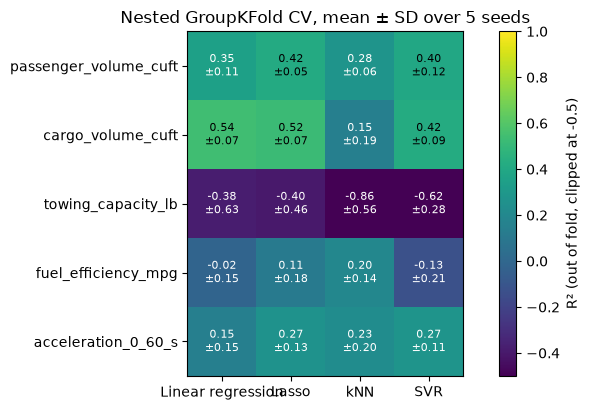

In [3]:
r2 = table[("R2", "mean")].unstack("model").loc[TARGETS, MODELS]
r2_sd = table[("R2", "std")].unstack("model").loc[TARGETS, MODELS]

fig, ax = plt.subplots(figsize=(7.5, 4.2))
im = ax.imshow(r2.clip(lower=-0.5).values, cmap="viridis", vmin=-0.5, vmax=1)
ax.set_xticks(range(r2.shape[1]), r2.columns)
ax.set_yticks(range(r2.shape[0]), r2.index)
for i in range(r2.shape[0]):
    for j in range(r2.shape[1]):
        ax.text(j, i, f"{r2.iat[i, j]:.2f}\n±{r2_sd.iat[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if r2.iat[i, j] < 0.4 else "black")
fig.colorbar(im, ax=ax, label="R² (out of fold, clipped at -0.5)")
ax.set_title("Nested GroupKFold CV, mean ± SD over 5 seeds")
fig.tight_layout()

best = r2.idxmax(axis=1).rename("best model").to_frame()
best["R2 mean"] = r2.max(axis=1)
best["R2 SD"] = [r2_sd.at[t, m] for t, m in best["best model"].items()]
best["runner-up"] = [r2.loc[t].drop(m).idxmax() for t, m in best["best model"].items()]
best["gap to runner-up"] = [r2.loc[t].max() - r2.loc[t].drop(m).max() for t, m in best["best model"].items()]
best.round(3)

### Exploratory: predicted vs actual for the best family per target (seed 0)

Each point is predicted by a model that never saw it, or its platform twin, during
fitting, tuning or feature selection. The family shown was chosen from the outer-CV table
above, so this is a family-by-family view, not the output of an unbiased selection procedure.

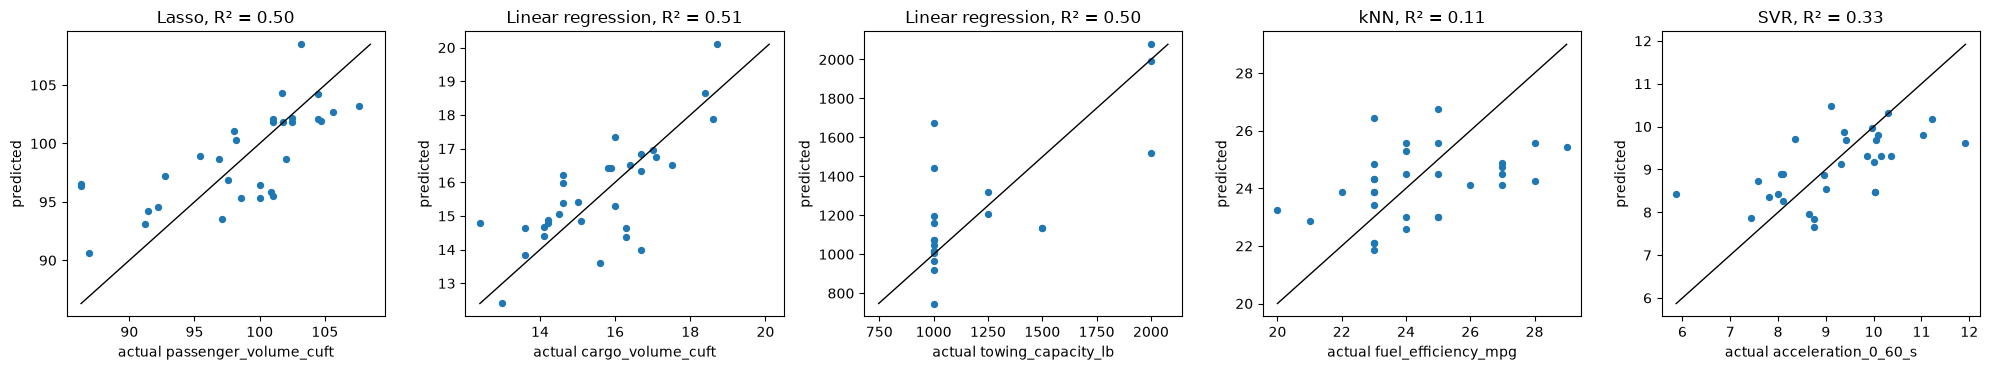

In [4]:
by_key = {(r.target, r.model, r.seed): r for r in nested}
fig, axes = plt.subplots(1, len(TARGETS), figsize=(4 * len(TARGETS), 3.8))
for ax, target in zip(axes, TARGETS):
    res = by_key[(target, best.at[target, "best model"], SEEDS[0])]
    _, y, _ = ds.target(target)
    ax.scatter(y, res.predictions, s=18)
    lims = [min(y.min(), res.predictions.min()), max(y.max(), res.predictions.max())]
    ax.plot(lims, lims, color="black", lw=1)
    ax.set_xlabel(f"actual {target}")
    ax.set_ylabel("predicted")
    ax.set_title(f"{res.model}, R² = {res.metrics['R2']:.2f}")
fig.tight_layout()

### How stable is the feature selection?

Share of the 25 outer folds (5 seeds × 5 folds) in which SFFS kept each design variable,
for the best family per target. Values near 0 or 1 mean a stable choice; values around 0.5
mean the selected subset depends on which handful of vehicles happened to be in the training fold.

In [5]:
freq = pd.DataFrame({
    t: selection_frequency([r for r in nested if r.target == t and r.model == best.at[t, "best model"]], FEATURES)
    for t in TARGETS
})
freq.round(2)

,passenger_volume_cuft,cargo_volume_cuft,towing_capacity_lb,fuel_efficiency_mpg,acceleration_0_60_s
fuel_tank_capacity_gal,0.72,0.96,0.92,0.12,0.72
engine_displacement_cc,0.16,0.04,0.92,1.00,1.00
front_track_width_in,0.28,0.12,0.48,0.12,0.64
wheelbase_in,0.64,0.44,0.72,0.16,0.60
ground_clearance_in,0.16,0.20,0.24,0.32,0.64
height_in,0.84,0.88,0.24,0.48,0.44
length_in,0.40,1.00,0.48,0.40,0.44
tire_width_mm,0.16,0.64,0.80,0.28,0.32
tire_diameter_in,0.08,0.20,0.80,0.04,0.32


## 2 · Baselines without SFFS and the complete selection procedure

On the **identical outer folds** (same seeds, same `GroupKFold`), three baselines skip SFFS:

* **Mean**: predicts the training-fold mean (R² = 0 reference, negative means worse than that);
* **Ridge (all features)**: L2 linear regression on all nine design variables, alpha tuned in the inner loop;
* **Lasso (no SFS)**: the Lasso family with the same alpha search but without SFFS. The gap to
  the SFFS Lasso above isolates what SFFS contributes.

The **complete procedure** chooses the family, its hyperparameters and its feature subset
inside the inner loop of each outer training fold, refits that choice and predicts the outer
test fold. Its outer score is the honest estimate for "let the pipeline pick the family".

In [6]:
t0 = time.time()
base = run_repeated(nested_cv, baselines, ds, TARGETS, group=True)
complete = run_repeated(nested_cv_complete, candidates, ds, TARGETS, group=True)
print(f"baselines + complete procedure: {time.time() - t0:.0f} s")

r2_all = results_table(nested + base + complete, metrics=("R2",))
compare_families = pd.DataFrame({
    "R2 mean": r2_all[("R2", "mean")], "R2 SD": r2_all[("R2", "std")],
}).unstack("model")
order = MODELS + BASELINES + ["Complete procedure"]
view = pd.concat([compare_families["R2 mean"][order].round(2).astype(str) + " ± " +
                  compare_families["R2 SD"][order].round(2).astype(str)], axis=1).loc[TARGETS]
view

baselines + complete procedure: 352 s


model,Linear regression,Lasso,kNN,SVR,Mean,Ridge (all features),Lasso (no SFS),Complete procedure
target,,,,,,,,
passenger_volume_cuft,0.35 ± 0.11,0.42 ± 0.05,0.28 ± 0.06,0.4 ± 0.12,-0.15 ± 0.12,0.46 ± 0.08,0.44 ± 0.06,0.36 ± 0.1
cargo_volume_cuft,0.54 ± 0.07,0.52 ± 0.07,0.15 ± 0.19,0.42 ± 0.09,-0.11 ± 0.07,0.42 ± 0.05,0.52 ± 0.07,0.47 ± 0.14
towing_capacity_lb,-0.38 ± 0.63,-0.4 ± 0.46,-0.86 ± 0.56,-0.62 ± 0.28,-0.13 ± 0.14,-0.56 ± 0.56,-0.59 ± 0.8,-0.41 ± 0.31
fuel_efficiency_mpg,-0.02 ± 0.15,0.11 ± 0.18,0.2 ± 0.14,-0.13 ± 0.21,-0.12 ± 0.06,0.05 ± 0.09,0.08 ± 0.17,-0.08 ± 0.24
acceleration_0_60_s,0.15 ± 0.15,0.27 ± 0.13,0.23 ± 0.2,0.27 ± 0.11,-0.06 ± 0.02,0.4 ± 0.12,0.36 ± 0.12,0.23 ± 0.12


Which family did the complete procedure pick in each outer fold? Frequent switching between
families is itself a sign that the data cannot tell the families apart.

In [7]:
picks = pd.DataFrame({t: pd.Series([f for r in complete if r.target == t for f in r.chosen_families]).value_counts()
                      for t in TARGETS}).fillna(0).astype(int).T.reindex(columns=MODELS, fill_value=0)
picks["R2 complete"] = [r2_all.loc[(t, "Complete procedure"), ("R2", "mean")] for t in TARGETS]
picks["R2 best family (post hoc)"] = [r2_all.loc[t].loc[MODELS, ("R2", "mean")].max() for t in TARGETS]
picks.round(2)

,Linear regression,Lasso,kNN,SVR,R2 complete,R2 best family (post hoc)
passenger_volume_cuft,11,0,1,13,0.36,0.42
cargo_volume_cuft,18,1,2,4,0.47,0.54
towing_capacity_lb,15,0,5,5,-0.41,-0.38
fuel_efficiency_mpg,8,0,14,3,-0.08,0.20
acceleration_0_60_s,11,1,2,11,0.23,0.27


### Does SFFS help? Stability and runtime

`jaccard` is the mean pairwise Jaccard similarity of the selected subsets across all 25 outer
folds (1 = the same subset every time), `mean_n_features` the subset size, `runtime_s_mean`
the wall time per nested run and `select_share` the fraction of fit time spent in SFFS.
Compare Lasso (SFFS) with Lasso (no SFS) and Ridge (all features).

In [8]:
stab = selection_stability(nested + base + complete)
stab.loc[[(t, m) for t in TARGETS for m in order]].round(2)

n_runs  n_folds  mean_n_features  \
target                model                                                    
passenger_volume_cuft Linear regression          5       25             3.84   
                      Lasso                      5       25             3.44   
                      kNN                        5       25             4.48   
                      SVR                        5       25             5.76   
                      Mean                       5       25             9.00   
                      Ridge (all features)       5       25             9.00   
                      Lasso (no SFS)             5       25             9.00   
                      Complete procedure         5       25             4.48   
cargo_volume_cuft     Linear regression          5       25             4.48   
                      Lasso                      5       25             4.04   
                      kNN                        5       25             2.48   
                      SVR                        5       25             4.96   
                      Mean                       5       25             9.00   
                      Ridge (all features)       5       25             9.00   
                      Lasso (no SFS)             5       25             9.00   
                      Complete procedure         5       25             4.60   
towing_capacity_lb    Linear regression          5       25             5.60   
                      Lasso                      5       25             2.96   
                      kNN                        5       25             2.48   
                      SVR                        5       25             5.28   
                      Mean                       5       25             9.00   
                      Ridge (all features)       5       25             9.00   
                      Lasso (no SFS)             5       25             9.00   
                      Complete procedure         5       25             5.20   
fuel_efficiency_mpg   Linear regression          5       25             2.52   
                      Lasso                      5       25             2.08   
                      kNN                        5       25             2.92   
                      SVR                        5       25             3.88   
                      Mean                       5       25             9.00   
                      Ridge (all features)       5       25             9.00   
                      Lasso (no SFS)             5       25             9.00   
                      Complete procedure         5       25             3.16   
acceleration_0_60_s   Linear regression          5       25             3.68   
                      Lasso                      5       25             3.08   
                      kNN                        5       25             3.12   
                      SVR                        5       25             5.12   
                      Mean                       5       25             9.00   
                      Ridge (all features)       5       25             9.00   
                      Lasso (no SFS)             5       25             9.00   
                      Complete procedure         5       25             4.12   

                                            jaccard  runtime_s_mean  \
target                model                                           
passenger_volume_cuft Linear regression        0.45           24.83   
                      Lasso                    0.40           26.85   
                      kNN                      0.39           34.77   
                      SVR                      0.56           30.82   
                      Mean                     1.00            0.47   
                      Ridge (all features)     1.00            5.13   
                      Lasso (no SFS)           1.00            4.88   
                      Complete procedure    

## 3 · Thesis protocol vs nested CV (optimistic comparison)

`flat_cv` re-implements the thesis protocol and is intentionally optimistic (not a valid generalisation estimate): tune and select features on all rows with
random 5-fold CV, then report 5-fold CV scores on the same folds. Nested CV is run twice,
with random folds and with `GroupKFold`, all with the same search space, search budget and
seeds. So

* flat − nested (random folds) is the optimism from reusing the scoring folds for model selection;
* nested (random folds) − nested (GroupKFold) is the effect of letting platform twins sit on
  both sides of a split.

In [9]:
t0 = time.time()
flat = run_repeated(flat_cv, candidates, ds, TARGETS, group=False)
nested_kfold = run_repeated(nested_cv, candidates, ds, TARGETS, group=False)
print(f"flat + nested KFold: {time.time() - t0:.0f} s")

def mean_r2(results):
    return results_table(results, metrics=("R2",))[("R2", "mean")]

compare = pd.DataFrame({
    "flat (thesis re-impl.)": mean_r2(flat),
    "nested, random KFold": mean_r2(nested_kfold),
    "nested, GroupKFold": mean_r2(nested),
})
compare["SD nested GroupKFold"] = table[("R2", "std")]
compare.loc[TARGETS].round(3)

flat + nested KFold: 362 s


flat (thesis re-impl.)  \
target                model                                       
passenger_volume_cuft Linear regression                   0.718   
                      Lasso                               0.701   
                      kNN                                 0.744   
                      SVR                                 0.735   
cargo_volume_cuft     Linear regression                   0.751   
                      Lasso                               0.739   
                      kNN                                 0.678   
                      SVR                                 0.752   
towing_capacity_lb    Linear regression                   0.633   
                      Lasso                               0.489   
                      kNN                                 0.486   
                      SVR                                 0.692   
fuel_efficiency_mpg   Linear regression                   0.360   
                      Lasso                               0.324   
                      kNN                                 0.448   
                      SVR                                 0.335   
acceleration_0_60_s   Linear regression                   0.589   
                      Lasso                               0.553   
                      kNN                                 0.564   
                      SVR                                 0.539   

                                         nested, random KFold  \
target                model                                     
passenger_volume_cuft Linear regression                 0.579   
                      Lasso                             0.591   
                      kNN                               0.562   
                      SVR                               0.528   
cargo_volume_cuft     Linear regression                 0.609   
                      Lasso                             0.648   
                      kNN                               0.393   
                      SVR                               0.526   
towing_capacity_lb    Linear regression                 0.016   
                      Lasso                            -0.109   
                      kNN                              -0.631   
                      SVR                              -0.426   
fuel_efficiency_mpg   Linear regression                 0.005   
                      Lasso                             0.179   
                      kNN                               0.155   
                      SVR                              -0.061   
acceleration_0_60_s   Linear regression                 0.320   
                      Lasso                             0.357   
                      kNN                               0.262   
                      SVR                               0.229   

                                         nested, GroupKFold  \
target                model                                   
passenger_volume_cuft Linear regression               0.353   
                      Lasso                           0.419   
                      kNN                             0.279   
                      SVR                             0.402   
cargo_volume_cuft     Linear regression               0.541   
                      Lasso                           0.520   
                      kNN                             0.149   
                      SVR                             0.420   
towing_capacity_lb    Linear regression              -0.379   
                      Lasso                          -0.400   
                      kNN                            -0.856   
                      SVR                            -0.620   
fuel_efficiency_mpg   Linear regression              -0.015   
                      Lasso                           0.114   
                      kNN                             0.196   
                      SVR                            -0.130   
a

Median over the five targets for each protocol. The last two columns are the
differences of the medians shown, so they can be checked by eye.

,flat (thesis re-impl.),"nested, random KFold","nested, GroupKFold",flat − nested KFold,nested KFold − GroupKFold
model,,,,,
Linear regression,0.633,0.320,0.145,0.313,0.175
Lasso,0.553,0.357,0.267,0.196,0.090
kNN,0.564,0.262,0.196,0.303,0.065
SVR,0.692,0.229,0.274,0.463,-0.044


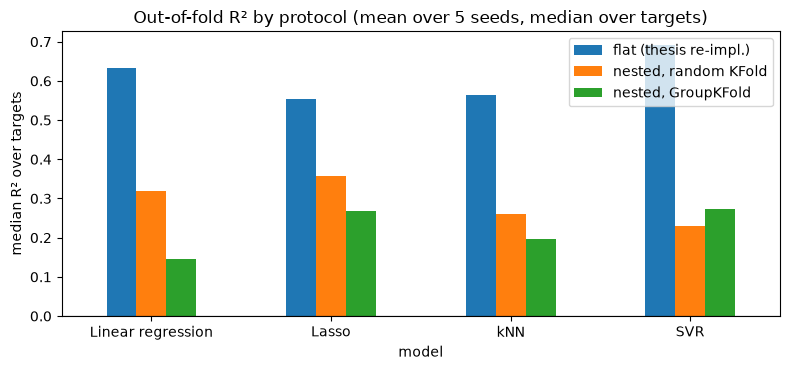

In [10]:
summary = compare.drop(columns="SD nested GroupKFold").groupby("model").median().loc[MODELS]
summary["flat − nested KFold"] = summary["flat (thesis re-impl.)"] - summary["nested, random KFold"]
summary["nested KFold − GroupKFold"] = summary["nested, random KFold"] - summary["nested, GroupKFold"]

ax = summary.iloc[:, :3].plot.bar(figsize=(8, 3.8), rot=0)
ax.set_ylabel("median R² over targets")
ax.axhline(0, color="black", lw=0.8)
ax.set_title("Out-of-fold R² by protocol (mean over 5 seeds, median over targets)")
plt.tight_layout()
summary.round(3)

Per-run artifacts of all protocols (metrics, per-sample out-of-fold predictions, fold
assignments, selections, captured warnings and run metadata) are saved to `results/runs/notebook/`,
which is gitignored. The published `results/benchmark/` directory that the README and
`scripts/make_figures.py` use is written by `python -m smalldata.run --preset benchmark`.

In [11]:
all_results = flat + nested_kfold + nested + base + complete
runs = pd.DataFrame([{"protocol": r.protocol, "target": r.target, "model": r.model, "seed": r.seed, **r.metrics}
                     for r in all_results])
out = save_run(all_results, ROOT / "results" / "runs" / "notebook",
               {"source": "notebooks/02_model_selection.ipynb", "N_ITER": N_ITER, "seeds": list(SEEDS)},
               data_path=DATA_PATH, y_by_target={t: ds.target(t)[1] for t in TARGETS}, repo_root=ROOT)
print(f"saved {len(all_results)} runs to {out.relative_to(ROOT)}")
runs.groupby("protocol").size()

saved 400 runs to results/runs/notebook


protocol
flat (thesis re-implementation)    100
nested, GroupKFold                 200
nested, random KFold               100
dtype: int64

## Reference: the thesis defence numbers

The thesis defence reported these CV R² values. `flat_cv` does **not** reproduce them,
for concrete reasons:

* **Rows.** The thesis held out the Honda Accord as a separate evaluation car (n = 30 in CV) and
  used the 1,225 lb towing placeholders as real values (n = 30 for towing). Here all 31 vehicles
  are in CV and towing has n = 20.
* **Metric.** The thesis averaged R² over the five test folds of about 6 vehicles. Here the main
  metric is R² on the pooled out-of-fold predictions; the per-fold mean is shown for comparison.
  Fold R² on 6 points is very noisy and can be far below zero.
* **Search.** The thesis drew 50 settings from uniform ranges on the raw target. Here every
  protocol draws N_ITER settings from log-uniform ranges on the standardised target.
* **Preprocessing.** The thesis mean-imputed ground clearance on the full dataset before
  splitting; here imputation is fitted inside the pipeline on training folds only.
* **Randomness.** The thesis used a single seed (42); here each of 5 seeds reshuffles the folds and redraws the search.

In [12]:
thesis = pd.DataFrame(
    {"Linear regression": [0.58, 0.71, -2.91, 0.22, 0.42],
     "Lasso": [0.59, 0.66, -2.83, 0.16, 0.35],
     "kNN": [0.75, 0.65, 0.24, 0.42, 0.31],
     "SVR": [0.78, 0.67, -0.18, 0.15, 0.38]},
    index=TARGETS,
).stack().rename("thesis defence (fold mean, n = 30)")
flat_table = results_table(flat, metrics=("R2", "R2_fold_mean"))
reference = pd.concat([
    thesis,
    flat_table[("R2_fold_mean", "mean")].rename("flat re-impl., fold mean"),
    flat_table[("R2", "mean")].rename("flat re-impl., pooled"),
    compare["nested, GroupKFold"].rename("nested GroupKFold, pooled"),
], axis=1).rename_axis(["target", "model"])
reference.round(2)

thesis defence (fold mean, n = 30)  \
target                model                                                   
passenger_volume_cuft Linear regression                                0.58   
                      Lasso                                            0.59   
                      kNN                                              0.75   
                      SVR                                              0.78   
cargo_volume_cuft     Linear regression                                0.71   
                      Lasso                                            0.66   
                      kNN                                              0.65   
                      SVR                                              0.67   
towing_capacity_lb    Linear regression                               -2.91   
                      Lasso                                           -2.83   
                      kNN                                              0.24   
                      SVR                                             -0.18   
fuel_efficiency_mpg   Linear regression                                0.22   
                      Lasso                                            0.16   
                      kNN                                              0.42   
                      SVR                                              0.15   
acceleration_0_60_s   Linear regression                                0.42   
                      Lasso                                            0.35   
                      kNN                                              0.31   
                      SVR                                              0.38   

                                         flat re-impl., fold mean  \
target                model                                         
passenger_volume_cuft Linear regression                      0.35   
                      Lasso                                  0.38   
                      kNN                                    0.56   
                      SVR                                    0.45   
cargo_volume_cuft     Linear regression                      0.60   
                      Lasso                                  0.60   
                      kNN                                    0.60   
                      SVR                                    0.62   
towing_capacity_lb    Linear regression                      0.34   
                      Lasso                                  0.12   
                      kNN                                    0.37   
                      SVR                                    0.43   
fuel_efficiency_mpg   Linear regression                     -0.04   
                      Lasso                                  0.00   
                      kNN                                    0.30   
                      SVR                                    0.11   
acceleration_0_60_s   Linear regression                      0.47   
                      Lasso                                  0.47   
                      kNN                                    0.45   
                      SVR                                    0.49   

                                         flat re-impl., pooled  \
target                model                                      
passenger_volume_cuft Linear regression                   0.72   
                      Lasso                               0.70   
                      kNN                                 0.74   
                      SVR                                 0.73   
cargo_volume_cuft     Linear regression                   0.75   
                      Lasso                               0.74   
                      kNN                                 0.68   
                      SVR                                 0.75   
towing_capacity_lb    Linear regression                   0.63   
                      Lasso                              

## Takeaways

Numbers are out-of-fold R², mean over 5 seeds; see the tables above. Reading them: the SD over
seeds mixes fold-assignment and search randomness and is not a confidence interval. The
published numbers in the README come from `results/benchmark/`, produced by the CLI with the
same configuration; this notebook's values should match them up to the parallel scheduling order.

* **Reusing the scoring folds for model selection inflates R² for every model on every
  target** (Section 3): the flat thesis protocol scores far above nested GroupKFold, and even
  reports positive R² for towing capacity, which no model predicts better than the mean under nested CV.
* **Platform twins add a further, smaller optimism**: random KFold vs GroupKFold.
* **Baselines without SFFS are competitive** (Section 2). Where Lasso (no SFS) or ridge on all
  features matches the SFFS families within the seed spread, SFFS is adding runtime and
  fold-to-fold instability rather than accuracy. Check the stability table before claiming a
  feature subset.
* **The complete procedure scores below the post-hoc best family** wherever the families are
  close, because choosing among near-equal families from noisy inner scores adds variance.
  The post-hoc best-family number is not an estimate of what an automatic procedure achieves.
* **What is predictable at this sample size.** Cargo volume and passenger volume are partly
  learnable from the design variables; acceleration and fuel efficiency are weak; towing capacity
  (n = 20, four distinct ratings) is not predictable.
* **Stable feature choices are the physically plausible ones** (length, fuel-tank capacity
  and height for cargo volume; engine displacement for fuel efficiency and acceleration); other
  picks change from fold to fold and are reported as frequencies.